# Nodes with labels: the cora co-authorship network

Authors are nodes, and every article with 3 to 6 authors is a filled simplex (`max_dim=5`; larger
articles stay as edges only). HHO's second layer gets one point per filled triangle: each article is
replaced by all its triangles of 3 co-authors (`layer2="all_simplices", max_dim=2`), so an article with
5 authors gives 10 points, and a triangle shared by several articles is one point. Each author
carries one of 7 scientific fields, used **only to evaluate** the embeddings, never to fit them.
This notebook shows how to measure what an embedding captures: a k-nearest-neighbor score for the
fields, the recovery of co-authors, and the agreement with the graph's distances. It then shows
how to tune the couplings μ and γ. It reproduces results of the paper.

The data (AHORN, revision 2) is downloaded from Zenodo on first use and cached, or read from
`HOHYPEMB_SNAPSHOT_DIR` when that variable is set.

In [1]:
import os
import sys
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

sys.path.insert(0, "..")  # finds hohypemb/ in the repository; not needed if you copied or installed it
import hohypemb as hh
from hohypemb.datasets.cora import load_cora_coauthorship

sc = load_cora_coauthorship(max_dim=5, data_dir=os.environ.get("HOHYPEMB_SNAPSHOT_DIR")).giant_component()
labels = sc.node_labels
sizes = Counter(len(s) for s in sc.higher_order_simplices())
print(sc.n_nodes, "authors,", sc.one_skeleton.number_of_edges(), "co-author pairs")
print("articles with k authors (k: count):", dict(sorted(sizes.items())))
print(pd.Series(labels).value_counts().to_string())

723 authors, 2243 co-author pairs
articles with k authors (k: count): {3: 179, 4: 61, 5: 28, 6: 13}
Probabilistic_Methods     224
Genetic_Algorithms        122
Case_Based                116
Rule_Learning             111
Reinforcement_Learning     66
Theory                     50
Neural_Networks            34


## 1. Embed and color by field

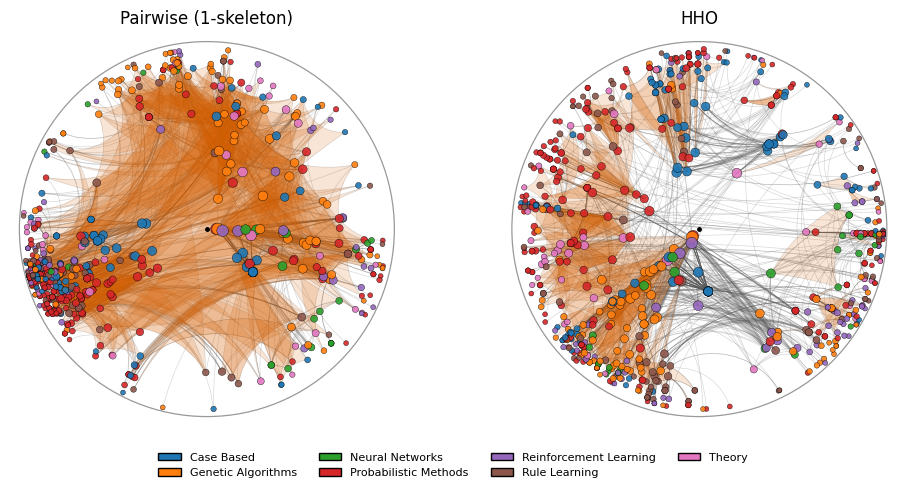

In [2]:
PARAMS = hh.presets.EMBEDDING_PARAMS["cora"]
MU, GAMMA = 5.0, 1.0
LAYER2 = {"layer2": "all_simplices", "max_dim": 2}  # one layer-2 point per filled triangle
classical = hh.ClassicalEmbedder(**PARAMS).fit(sc, seed=0)
hho = hh.HHOEmbedder(mu=MU, gamma=GAMMA, **LAYER2, **PARAMS).fit(sc, seed=0)

fields = sorted(set(labels.tolist()))
field_colors = {f: plt.get_cmap("tab10")(i) for i, f in enumerate(fields)}
fig = hh.plotting.plot_comparison(sc, classical, hho, node_colors=[field_colors[f] for f in labels],
                                  legend={f.replace("_", " "): c for f, c in field_colors.items()},
                                  titles=("Pairwise (1-skeleton)", "HHO"))
fig.subplots_adjust(bottom=0.12)
plt.show()

*What to expect:* each dot is an author, colored by field, and the shaded regions are the
articles. The pairwise embedding is computed from the co-author edges alone, so each article's
members (shaded) are spread across the disk; HHO pulls them together. Fields are visibly mixed
in both disks.

## 2. Does the geometry carry the fields?

k-nearest-neighbor classification of the field from the embedding distances: for each test author,
the field is predicted by a vote among its 10 nearest training authors in the embedding; the score
is the fraction predicted correctly. We use 5-fold stratified cross-validation repeated 10 times.
`make_splits` draws the folds **once**, and both embeddings are scored on the same folds, so their
scores are directly comparable.

pairwise  accuracy 0.384  95% CI [0.376, 0.392]
HHO       accuracy 0.411  95% CI [0.402, 0.421]
majority class 0.310


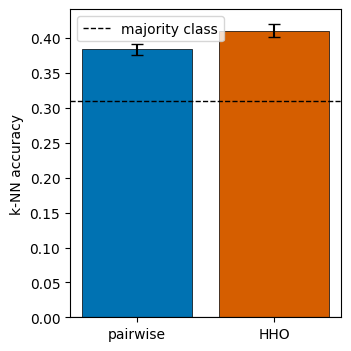

In [3]:
splits = hh.evaluation.make_splits(labels, n_splits=5, n_repeats=10, seed=0)
majority = pd.Series(labels).value_counts().iloc[0] / len(labels)


def knn_accuracy(result, folds=splits):
    return hh.evaluation.node_classification(result.distance_matrix(), labels, folds, k=10)["accuracy"]


acc = {"pairwise": knn_accuracy(classical), "HHO": knn_accuracy(hho)}
ci = {name: hh.evaluation.bootstrap_ci(a, n_boot=2000, seed=0) for name, a in acc.items()}
for name, a in acc.items():
    print(f"{name:9s} accuracy {a.mean():.3f}  95% CI [{ci[name][0]:.3f}, {ci[name][1]:.3f}]")
print(f"majority class {majority:.3f}")

fig, ax = plt.subplots(figsize=(3.5, 4))
hh.plotting.plot_paired_bars(ax, list(acc), [a.mean() for a in acc.values()],
                             [ci[n][0] for n in acc], [ci[n][1] for n in acc],
                             [hh.plotting.PALETTE["classical"], hh.plotting.PALETTE["hho"]])
ax.axhline(majority, color="black", linestyle="--", linewidth=1, label="majority class")
ax.set_ylabel("k-NN accuracy")
ax.legend()
plt.show()

*What to expect:* both methods sit well above the majority-class rate (0.31), at about 0.38 for
pairwise and 0.41 for HHO, and their 95% intervals do not overlap.

## 3. Recover co-authors

For each author who wrote at least one article with 3 to 6 authors (the simplices; larger articles and
2-author articles are edges only), which fraction of their 5 nearest neighbors in the embedding
share such an article with them? `partner_precision_at_k` answers this, its default groups being the
simplices. It measures how well each embedding keeps the input articles together: the pairwise
embedding sees the same co-author edges, but not the articles as groups.

500 eligible authors; mean precision@5: classical 0.099, HHO 0.163 (paired Wilcoxon p = 2.9e-16)


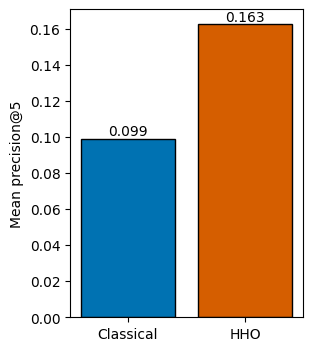

In [4]:
prec_cl = hh.markers.partner_precision_at_k(sc, classical, k=5)
prec_hho = hh.markers.partner_precision_at_k(sc, hho, k=5)
differs = np.any(prec_hho.precision != prec_cl.precision)
p = wilcoxon(prec_hho.precision, prec_cl.precision).pvalue if differs else float("nan")
print(f"{len(prec_hho.eligible)} eligible authors; mean precision@5: classical {prec_cl.mean:.3f}, "
      f"HHO {prec_hho.mean:.3f} (paired Wilcoxon p = {p:.1e})")
fig, ax = plt.subplots(figsize=(3, 4))
hh.plotting.plot_partner_precision(ax, prec_cl, prec_hho)
plt.show()

*What to expect:* among the 500 eligible authors, on average 9.9% of the 5 nearest neighbors
share an article under the pairwise embedding and 16.3% under HHO (paired Wilcoxon p = 2.9e-16). As
with the complex partners in `03_ecoli.ipynb`, HHO brings the members of the groups closer together.

## 4. Compare with the graph's distances

Does the distance in the disk follow the number of hops in the co-author graph? We compute the
Spearman correlation between the two over all pairs of authors (`global_distortion`), and the hop
count up to which the median distance keeps growing.

Spearman rho, distance vs hops: classical -0.078, HHO 0.417


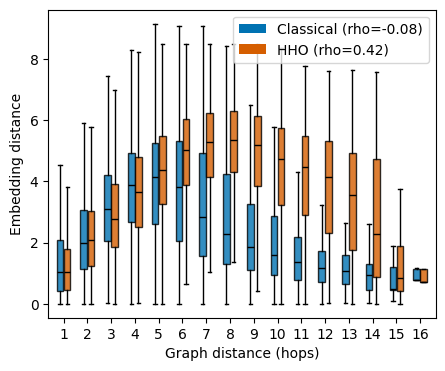

In [5]:
dist_cl = hh.markers.global_distortion(sc, classical)
dist_hho = hh.markers.global_distortion(sc, hho)
print(f"Spearman rho, distance vs hops: classical {dist_cl.spearman_rho:.3f}, HHO {dist_hho.spearman_rho:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
hh.plotting.plot_distortion(ax, dist_cl, dist_hho)
plt.show()

In [6]:
def peak_hops(d):
    med = [np.median(x) for x in d.per_hop]
    k = int(np.argmax(med))
    share = sum(len(x) for x in d.per_hop[:k + 1]) / sum(len(x) for x in d.per_hop)
    return d.hop_values[k], share


for name, d in (("classical", dist_cl), ("HHO", dist_hho)):
    peak, share = peak_hops(d)
    print(f"{name:9s} median distance peaks at {peak} hops; {share:.0%} of the pairs are within {peak} hops")

classical median distance peaks at 5 hops; 58% of the pairs are within 5 hops
HHO       median distance peaks at 8 hops; 93% of the pairs are within 8 hops


*What to expect:* under the pairwise embedding the median distance grows with the number of hops only
up to 5 hops, which covers 58% of the pairs (ρ = -0.078); under HHO it grows up to 8 hops, which covers 93% of the
pairs (ρ = 0.417).

How the gains depend on μ:

In [7]:
rows = {"pairwise": classical}
for mu in (3, 5, 7):
    rows[f"HHO, μ = {mu}"] = hh.HHOEmbedder(mu=mu, gamma=1, **LAYER2, **PARAMS).fit(sc, seed=0)
table = pd.DataFrame({
    "co-author precision@5": {n: hh.markers.partner_precision_at_k(sc, r, k=5).mean for n, r in rows.items()},
    "distortion ρ": {n: hh.markers.global_distortion(sc, r).spearman_rho for n, r in rows.items()},
})
print(table.round(3).to_string())

            co-author precision@5  distortion ρ
pairwise                    0.099        -0.078
HHO, μ = 3                  0.108         0.051
HHO, μ = 5                  0.163         0.417
HHO, μ = 7                  0.170         0.457


*What to expect:* both gains grow with μ over this range: co-author precision is 0.108, 0.163 and
0.170 at μ = 3, 5 and 7, and the distortion ρ 0.051, 0.417 and 0.457. At μ = 3 the distortion is close
to that of the pairwise embedding.

## 5. Tune the coupling μ and γ

μ couples a node to the layer-2 points (here, filled triangles) that contain it; γ couples two
layer-2 points that share more than one node (two triangles with a common edge).

The score tuned here is the k-NN score of section 2. For each test author, the field is predicted
by a majority vote among its 10 nearest neighbors in the embedding (hyperbolic distance), using
only authors of the training folds. The score is the fraction of test authors whose field is
predicted correctly, averaged over the folds. The grid below uses 5 folds × 4 repeats = 20 folds,
to keep it fast.

In [8]:
splits20 = hh.evaluation.make_splits(labels, n_splits=5, n_repeats=4, seed=0)
MU_VALUES = np.array([0.5, 1, 2, 3, 5, 7, 10, 15, 20])
GAMMA_VALUES = np.array([0.0, 0.5, 1.0, 2.0])
grid = np.zeros((len(GAMMA_VALUES), len(MU_VALUES)))
grid_lo, grid_hi = np.zeros_like(grid), np.zeros_like(grid)
for gi, gamma in enumerate(GAMMA_VALUES):
    for mi, mu in enumerate(MU_VALUES):
        res = hh.HHOEmbedder(mu=float(mu), gamma=float(gamma), **LAYER2, **PARAMS).fit(sc, seed=0)
        folds = knn_accuracy(res, splits20)
        grid[gi, mi] = folds.mean()
        grid_lo[gi, mi], grid_hi[gi, mi] = hh.evaluation.bootstrap_ci(folds, n_boot=1000, seed=0)
baseline20 = knn_accuracy(classical, splits20).mean()
best_g, best_m = np.unravel_index(np.argmax(grid), grid.shape)
print(f"pairwise baseline {baseline20:.4f}; best HHO {grid[best_g, best_m]:.4f} "
      f"at mu = {MU_VALUES[best_m]:g}, gamma = {GAMMA_VALUES[best_g]:g}")
pd.DataFrame(grid, index=GAMMA_VALUES, columns=MU_VALUES).round(3)

pairwise baseline 0.3787; best HHO 0.4270 at mu = 7, gamma = 0


,0.5,1.0,2.0,3.0,5.0,7.0,10.0,15.0,20.0
0.0,0.393,0.404,0.388,0.425,0.412,0.427,0.314,0.309,0.308
0.5,0.392,0.391,0.389,0.425,0.412,0.427,0.314,0.309,0.308
1.0,0.400,0.393,0.383,0.426,0.412,0.427,0.314,0.309,0.308
2.0,0.378,0.355,0.392,0.403,0.408,0.427,0.314,0.309,0.308


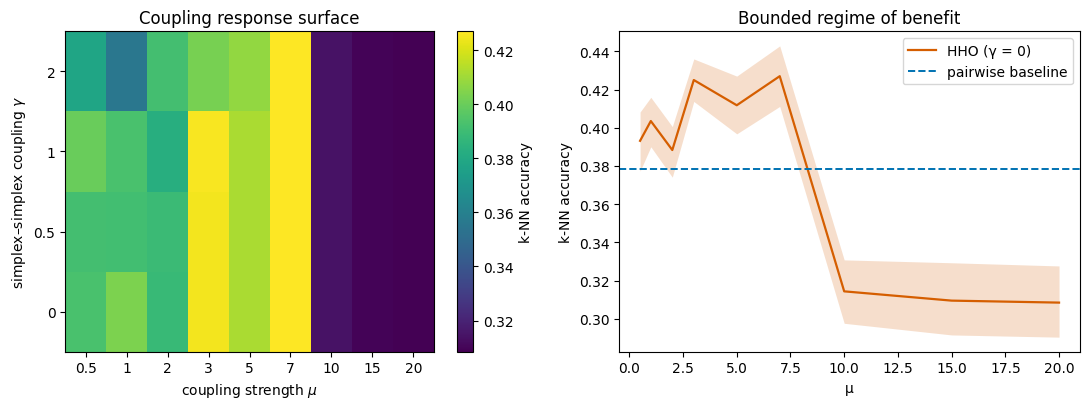

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
hh.plotting.plot_response_surface(axes[0], MU_VALUES, GAMMA_VALUES, grid, cbar_label="k-NN accuracy")
axes[0].set_title("Coupling response surface")
hh.plotting.plot_slice_with_ci(axes[1], MU_VALUES, grid[best_g], grid_lo[best_g], grid_hi[best_g],
                               label=f"HHO (γ = {GAMMA_VALUES[best_g]:g})", color=hh.plotting.PALETTE["hho"])
axes[1].axhline(baseline20, color=hh.plotting.PALETTE["classical"], linestyle="--", linewidth=1.4,
                label="pairwise baseline")
axes[1].set_xlabel("μ")
axes[1].set_ylabel("k-NN accuracy")
axes[1].set_title("Bounded regime of benefit")
axes[1].legend()
fig.tight_layout()
plt.show()

*What to expect:* HHO beats the pairwise baseline: the best accuracy is 0.427 at μ = 7 (the first
row, γ = 0, is printed; every γ gives the same value there), against 0.379 for the pairwise embedding.
This is the best cell of the grid on these 20 folds; the untuned μ = 5 of section 1 already gives
0.411 against 0.384 (section 2). The gain exists over a bounded range of μ. On cora, a coupling that
is too strong (μ ≥ 10) pulls nodes toward their triangles so hard that the result falls below the
pairwise embedding. For μ ≥ 7 the value of γ does not change the accuracy; at smaller μ it moves it by
up to 5 points (μ = 1: 0.404 at γ = 0, 0.355 at γ = 2).